In [1]:
%pip install pandas numpy matplotlib seaborn openpyxl

Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)

All libraries imported successfully!
Pandas version: 2.3.3


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_excel("../data/sales_cleaned.xlsx")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nColumn Information:")
df.info()

Dataset Shape: (1000, 15)

First 5 Records:


,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales,Month,Year,Month_Name
0,ORD100002,2025-02-25,CUST5529,Customer_227,30,Female,Bengaluru,Rice,Grocery,7,2829.77,19808.39,2,2025,February
1,ORD100003,2025-10-14,CUST3127,Customer_182,63,Male,Bengaluru,Book,Education,5,27906.16,139530.80,10,2025,October
2,ORD100004,2025-05-13,CUST8887,Customer_487,62,Female,Bengaluru,Book,Education,8,37491.06,299928.48,5,2025,May
3,ORD100005,2025-12-02,CUST2515,Customer_470,65,Female,Kolkata,Mobile,Electronics,9,28541.36,256872.24,12,2025,December
4,ORD100006,2025-11-20,CUST4796,Customer_380,44,Male,Bengaluru,Rice,Grocery,10,14036.59,140365.90,11,2025,November



Column Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Order_ID       1000 non-null   object        
 1   Order_Date     1000 non-null   datetime64[ns]
 2   Customer_ID    1000 non-null   object        
 3   Customer_Name  1000 non-null   object        
 4   Age            1000 non-null   int64         
 5   Gender         1000 non-null   object        
 6   City           1000 non-null   object        
 7   Product        1000 non-null   object        
 8   Category       1000 non-null   object        
 9   Quantity       1000 non-null   int64         
 10  Unit_Price     1000 non-null   float64       
 11  Total_Sales    1000 non-null   float64       
 12  Month          1000 non-null   int64         
 13  Year           1000 non-null   int64         
 14  Month_Name     1000 non-null   object        
dtypes

In [5]:
print(df.isnull().sum())

Order_ID         0
Order_Date       0
Customer_ID      0
Customer_Name    0
Age              0
Gender           0
City             0
Product          0
Category         0
Quantity         0
Unit_Price       0
Total_Sales      0
Month            0
Year             0
Month_Name       0
dtype: int64


In [6]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [7]:
df.describe()

,Order_Date,Age,Quantity,Unit_Price,Total_Sales,Month,Year
count,1000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,2025-07-03 11:19:40.800000,41.353000,5.435000,25486.783410,139399.439650,6.518000,2025.005000
min,2025-01-01 00:00:00,18.000000,1.000000,145.780000,437.340000,1.000000,2025.000000
25%,2025-03-30 18:00:00,30.000000,3.000000,13895.722500,47066.632500,3.000000,2025.000000
50%,2025-07-01 00:00:00,41.000000,5.000000,25398.740000,108594.025000,6.000000,2025.000000
75%,2025-10-07 06:00:00,53.000000,8.000000,37512.382500,203722.882500,10.000000,2025.000000
max,2026-01-01 00:00:00,65.000000,10.000000,49997.530000,493677.500000,12.000000,2026.000000
std,NaN,13.683626,2.838632,14179.402361,114100.051546,3.498845,0.070569


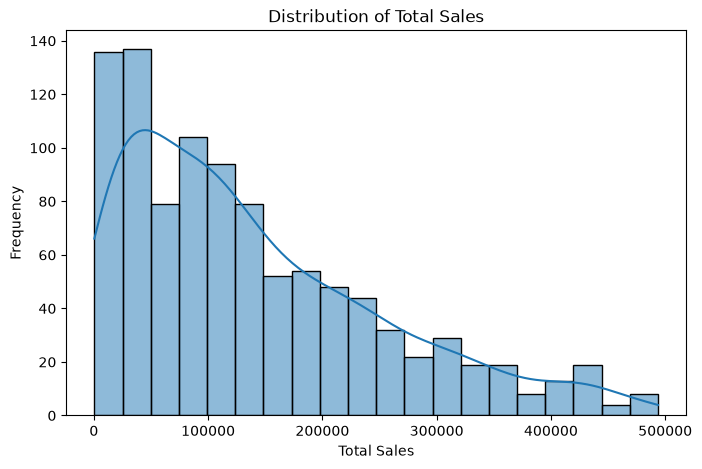

In [8]:
plt.figure(figsize=(8, 5))

sns.histplot(df['Total_Sales'], bins=20, kde=True)

plt.title('Distribution of Total Sales')
plt.xlabel('Total Sales')
plt.ylabel('Frequency')

plt.show()

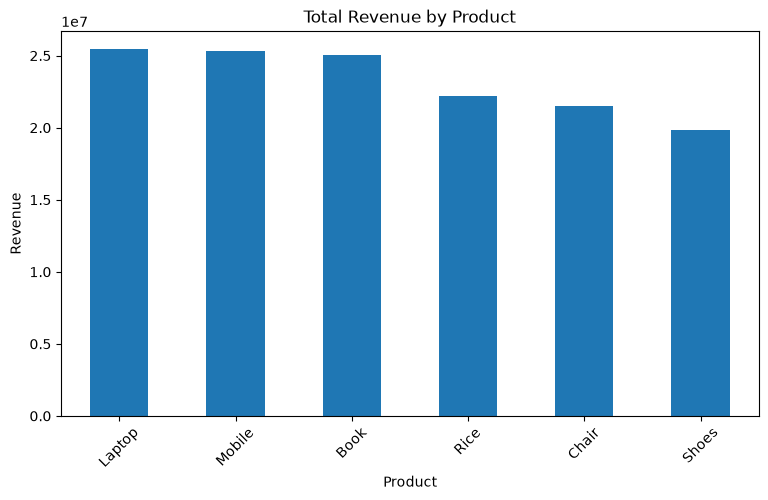

In [9]:
product_sales = df.groupby('Product')['Total_Sales'].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 5))

product_sales.plot(kind='bar')

plt.title('Total Revenue by Product')
plt.xlabel('Product')
plt.ylabel('Revenue')
plt.xticks(rotation=45)

plt.show()

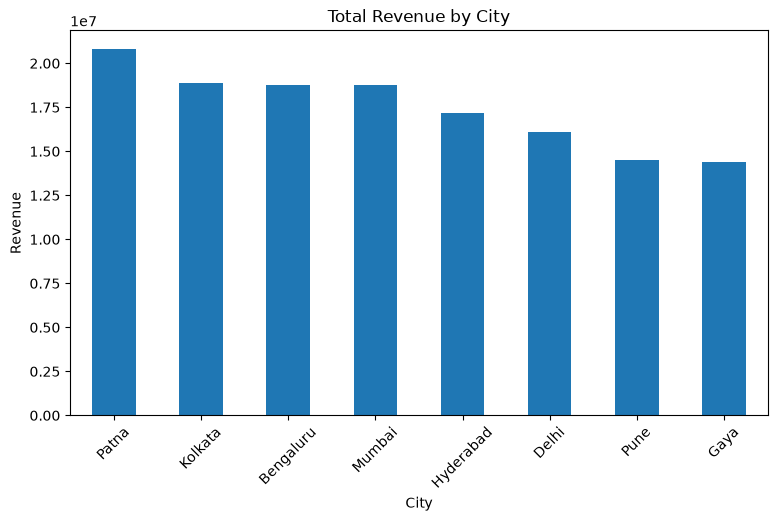

In [10]:
city_sales = df.groupby('City')['Total_Sales'].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 5))

city_sales.plot(kind='bar')

plt.title('Total Revenue by City')
plt.xlabel('City')
plt.ylabel('Revenue')
plt.xticks(rotation=45)

plt.show()

In [11]:
for col in ['Gender', 'City', 'Product', 'Category']:
    print(f"\n{col} Distribution:")
    print(df[col].value_counts())


Gender Distribution:
Gender
Male      511
Female    489
Name: count, dtype: int64

City Distribution:
City
Patna        148
Kolkata      133
Mumbai       131
Hyderabad    125
Delhi        125
Bengaluru    122
Gaya         117
Pune          99
Name: count, dtype: int64

Product Distribution:
Product
Mobile    184
Book      178
Laptop    170
Chair     159
Shoes     156
Rice      153
Name: count, dtype: int64

Category Distribution:
Category
Electronics    354
Education      178
Furniture      159
Fashion        156
Grocery        153
Name: count, dtype: int64


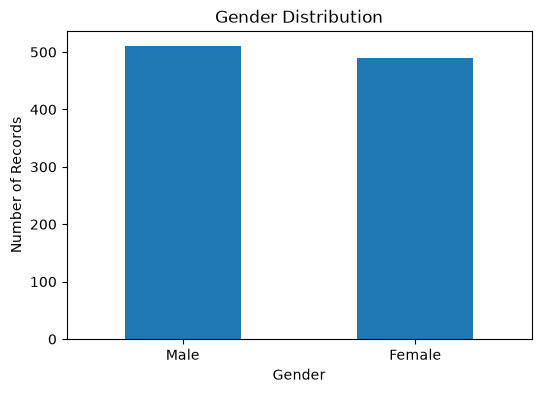

In [12]:
plt.figure(figsize=(6, 4))

df['Gender'].value_counts().plot(
    kind='bar',
    title='Gender Distribution'
)

plt.xlabel('Gender')
plt.ylabel('Number of Records')
plt.xticks(rotation=0)
plt.show()

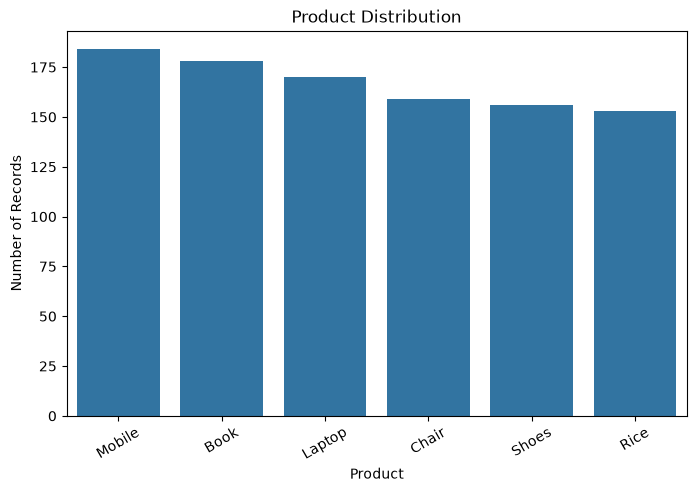

In [13]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Product', order=df['Product'].value_counts().index)

plt.title('Product Distribution')
plt.xlabel('Product')
plt.ylabel('Number of Records')
plt.xticks(rotation=30)
plt.show()

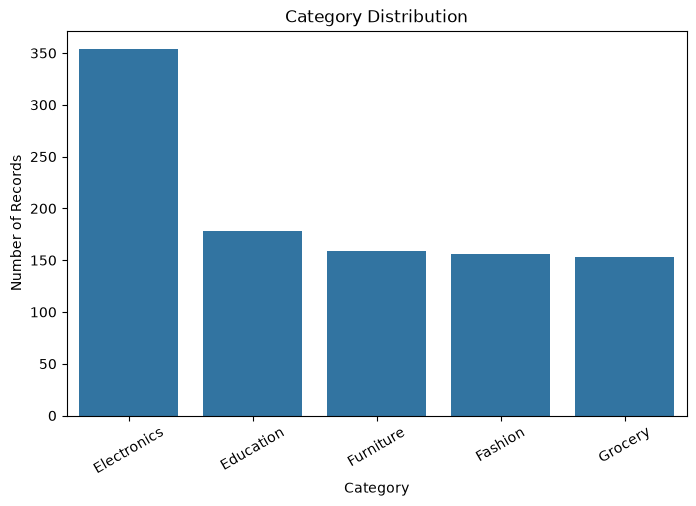

In [14]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Category', order=df['Category'].value_counts().index)

plt.title('Category Distribution')
plt.xlabel('Category')
plt.ylabel('Number of Records')
plt.xticks(rotation=30)
plt.show()

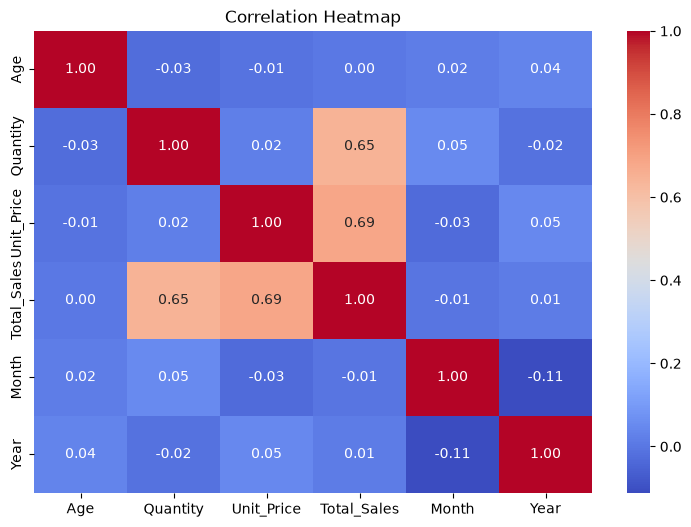

In [16]:
numeric_df = df.select_dtypes(include='number')

correlation = numeric_df.corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

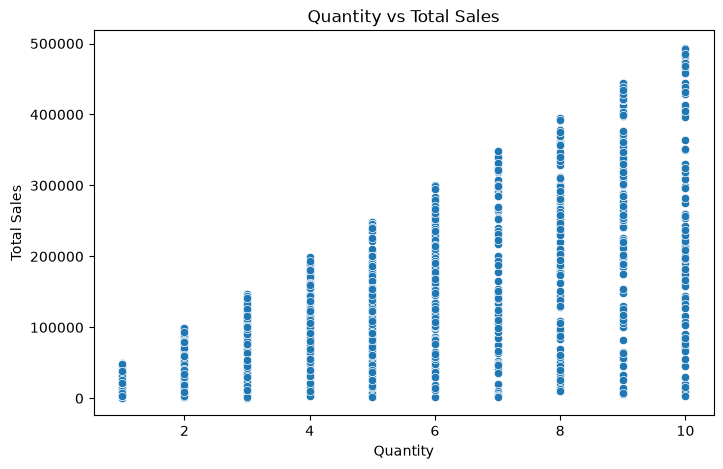

In [17]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Quantity',
    y='Total_Sales'
)

plt.title('Quantity vs Total Sales')
plt.xlabel('Quantity')
plt.ylabel('Total Sales')

plt.show()